In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install miplib

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 218 kB 5.0 MB/s 
     |████████████████████████████████| 48.4 MB 2.2 MB/s 
     |████████████████████████████████| 453 kB 65.3 MB/s 
     |████████████████████████████████| 86 kB 3.1 MB/s 
  Created wheel for miplib: filename=miplib-1.0.6-cp37-cp37m-linux_x86_64.whl size=316329 sha256=7e64e74aa3de2b994e1a6ea914e3db4782fcf7cdf501c594693dd8683896eb51
  Stored in directory: /root/.cache/pip/wheels/23/ed/5a/00f678f11987f711299f7ab590bdbd0fbf8bea4553c189ee08
  Created wheel for pims: filename=PIMS-0.6.1-py3-none-any.whl size=82636 sha256=527869d91a40b94fac19c32b143c1324a46640214df2298d6e33b0aa78922b1a
  Stored in directory: /root/.cache/pip/wheels/8e/d5/a9/f702433436655b7a2bc7ff93efd742587dd5abd44f7e406917
  Created wheel for psf: filename=psf-2021.6.6-cp37-cp37m-linux_x86_64.whl size=58462 sha256=39c5b55094892ab4e41b31ee4df79ea1a21d9cd62d1e766b9b4de54cb

In [5]:
%matplotlib inline

import os
import numpy as np
import imageio
import matplotlib.pyplot as plt

import miplib.ui.plots.image as showim
import miplib.data.io.read as imread
import miplib.processing.image as imops
from miplib.data.containers.image import Image

# import miplib.analysis.resolution.fourier_ring_correlation as frc
from miplib.data.containers.fourier_correlation_data import FourierCorrelationData,\
FourierCorrelationDataCollection
from miplib.analysis.resolution import analysis as fsc_analysis, fourier_ring_correlation
from miplib.processing import windowing
import miplib.data.iterators.fourier_ring_iterators as iterators

import miplib.ui.plots.frc as frcplots
# from miplib.processing.fft_filters import fft_filter, butterworth_fft_filter, gaussian_fft_filter
from miplib.ui.cli import miplib_entry_point_options as options

import urllib.request as dl

from miplib.data.core.dictionary import FixedDictionary

In [6]:
args_list = ("None --bin-delta=1  --frc-curve-fit-type=smooth-spline "
            " --resolution-threshold-criterion=half-bit").split()
            
args = options.get_frc_script_options(args_list)

print (args)

Namespace(carma_det_idx=0, carma_gate_idx=0, channel=0, d_angle=20, d_bin=1, d_extract_angle=5.0, debug=False, directory='None', disable_hamming=False, enhance_contrast_on_save=False, evaluate_results=False, frc_curve_fit_degree=8, frc_curve_fit_type='smooth-spline', frc_mode='one-image', hollow_iterator=False, jupyter=False, min_filter=False, pathout=None, plot_size=(2.5, 2.5), resol_square=False, resolution_point_sigma=0.01, resolution_snr_value=0.25, resolution_threshold_criterion='half-bit', resolution_threshold_curve_fit_degree=3, resolution_threshold_value=0.14285714285714285, save_plots=False, scale=100, show_image=False, show_plots=False, temp_dir=None, test_drive=False, verbose=False, working_directory='/home/sami/Data')


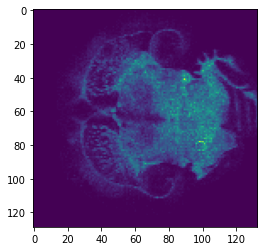

In [29]:
directory = '/content/drive/MyDrive/realesrgan_data/new_brains_LD_REIMS/lr_selected/'
image = imageio.imread(directory + 'brain_peak1331.png')
image = Image(image[:, :, 0],[100.0,100.0])
spacing = image.spacing

plt.imshow(image)
plt.show()

In [61]:
class FRC(object):
    """
    A class for calcuating 2D Fourier ring correlation. Contains
    methods to calculate the FRC as well as to plot the results.
    """

    def __init__(self, image1, image2, iterator):
        assert isinstance(image1, Image)
        assert isinstance(image2, Image)

        if image1.shape != image2.shape or tuple(image1.spacing) != tuple(image2.spacing):
            raise ValueError("The image dimensions do not match")
        if image1.ndim != 2:
            raise ValueError("Fourier ring correlation requires 2D images.")

        self.pixel_size = image1.spacing[0]

        # Expand to square
        image1 = imops.zero_pad_to_cube(image1)
        image2 = imops.zero_pad_to_cube(image2)

        self.iterator = iterator
        # Calculate power spectra for the input images.
        self.fft_image1 = np.fft.fftshift(np.fft.fft2(image1))
        self.fft_image2 = np.fft.fftshift(np.fft.fft2(image2))

        # Get the Nyquist frequency
        self.freq_nyq = int(np.floor(image1.shape[0] / 2.0))

    def execute(self):
        """
        Calculate the FRC
        :return: Returns the FRC results.

        """
        radii = self.iterator.radii
        c1 = np.zeros(radii.shape, dtype=np.float32)
        c2 = np.zeros(radii.shape, dtype=np.float32)
        c3 = np.zeros(radii.shape, dtype=np.float32)
        points = np.zeros(radii.shape, dtype=np.float32)

        for ind_ring, idx in self.iterator:
            subset1 = self.fft_image1[ind_ring]
            subset2 = self.fft_image2[ind_ring]
            c1[idx] = np.sum(subset1 * np.conjugate(subset2)).real
            c2[idx] = np.sum(np.abs(subset1) ** 2)
            c3[idx] = np.sum(np.abs(subset2) ** 2)

            points[idx] = len(subset1)

        # Calculate FRC
        spatial_freq = radii.astype(np.float32) / self.freq_nyq
        n_points = np.array(points)

        with np.errstate(divide="ignore", invalid="ignore"):
            frc = np.abs(c1) / np.sqrt(c2 * c3)
            frc[frc == np.inf] = 0.0
            frc = np.nan_to_num(frc)


        data_set = FourierCorrelationData()
        data_set.correlation["correlation"] = frc
        data_set.correlation["frequency"] = spatial_freq
        data_set.correlation["points-x-bin"] = n_points

        return data_set

In [62]:
def frc_resolution(img_dir, spacing): 
  image = imageio.imread(img_dir)
  image = Image(image[:, :, 0], spacing)
  spacing = image.spacing
  average = True
  z_correction=0
  resolutions = []
  frc_data = FourierCorrelationDataCollection()

  if not args.disable_hamming:
      image = Image(windowing.apply_hamming_window(image), spacing)

      # Split and make sure that the images are the same size
      image1, image2 = imops.checkerboard_split(image)
  #     image1, image2 = imops.reverse_checkerboard_split(image)
      image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)

      # Run FRC
      iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
      frc_task = FRC(image1, image2, iterator)
      frc_data[0] = frc_task.execute()

      if average:
          # Split and make sure that the images are the same size
          image1, image2 = imops.reverse_checkerboard_split(image)
          image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)
          iterator = iterators.FourierRingIterator(image1.shape, args.d_bin)
          frc_task = FRC(image1, image2, iterator)

          frc_data[0].correlation["correlation"] *= 0.5
          frc_data[0].correlation["correlation"] += 0.5*frc_task.execute().correlation["correlation"]

      freqs = frc_data[0].correlation["frequency"].copy()

      analyzer = fsc_analysis.FourierCorrelationAnalysis(frc_data, image1.spacing[0], args)

      result = analyzer.execute(z_correction=z_correction)[0]
      resolutions.append(result.resolution['resolution'])
      return resolutions[0]

In [44]:
lr_folder = '/content/drive/MyDrive/realesrgan_data/new_brains_LD_REIMS/lr_selected/'
res_folder = '/content/drive/MyDrive/realesrgan_data/new_brains_LD_REIMS/res_selected/'
enh_folder = '/content/drive/MyDrive/realesrgan_data/new_brains_LD_REIMS/enh_selected/'
hr_folder = '/content/drive/MyDrive/realesrgan_data/new_brains_LD_REIMS/hr_selected/'

In [69]:
# lr[1003, 984, 1331]
# hr[716, 696, 1049]

lr_984_resolution = frc_resolution(lr_folder+'brain_peak984.png', [100,100])
print('reoslution of lr 984 is ' + str(lr_984_resolution))
res_984_resolution = frc_resolution(res_folder+'brain_peak984.png', [25,25])
print('reoslution of res 984 is ' + str(res_984_resolution))
hr_696_resolution = frc_resolution(hr_folder+'brain_peak696.png', [25,25])
print('reoslution of hr 696 is ' + str(hr_696_resolution))
enh_696_resolution = frc_resolution(enh_folder+'brain_peak696.png', [6.25, 6.25])
print('reoslution of enh 696 is ' + str(enh_696_resolution))
print('----')
lr_1003_resolution = frc_resolution(lr_folder+'brain_peak1003.png', [100.0,100.0])
print('reoslution of lr 1003 is ' + str(lr_1003_resolution))
res_1003_resolution = frc_resolution(res_folder+'brain_peak1003.png', [25,25])
print('reoslution of res 1003 is ' + str(res_1003_resolution))
hr_716_resolution = frc_resolution(hr_folder+'brain_peak716.png', [25.0,25.0])
print('reoslution of hr 716 is ' + str(hr_716_resolution))
enh_716_resolution = frc_resolution(enh_folder+'brain_peak716.png', [6.25,6.25])
print('reoslution of enh 716 is ' + str(enh_716_resolution))
print('----')
lr_1331_resolution = frc_resolution(lr_folder+'brain_peak1331.png', [100.0,100.0])
print('reoslution of lr 1331 is ' + str(lr_1331_resolution))
res_1331_resolution = frc_resolution(res_folder+'brain_peak1331.png', [25,25])
print('reoslution of res 1331 is ' + str(res_1331_resolution))
hr_1049_resolution = frc_resolution(hr_folder+'brain_peak1049.png', [25.0, 25.0])
print('reoslution of hr 1049 is ' + str(hr_1049_resolution))
enh_1049_resolution = frc_resolution(enh_folder+'brain_peak1049.png', [6.25,6.25])
print('reoslution of enh 1049 is ' + str(enh_1049_resolution))

reoslution of lr 984 is 342.68328762721785
reoslution of res 984 is 91.93813355664601
reoslution of hr 696 is 162.36145761959858
reoslution of enh 696 is 23.548487121753325
----
reoslution of lr 1003 is 333.51097484179104
reoslution of res 1003 is 91.28639309281296
reoslution of hr 716 is 157.18760656272053
reoslution of enh 716 is 19.90220835585386
----
reoslution of lr 1331 is 351.01276610491277
reoslution of res 1331 is 85.95548349440526
reoslution of hr 1049 is 122.47711198421398
reoslution of enh 1049 is 27.633396790381138
